 Load data and prepare PCA + autoencoder features

In [1]:
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from sklearn.decomposition import PCA

 Project paths

In [2]:
PROJECT_DIR = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
matches = list(PROJECT_DIR.rglob("train_v2.csv"))

if not matches:
    raise FileNotFoundError(f"Could not find train_v2.csv under {PROJECT_DIR}")

TARGET_DIR = matches[0].parent
train = pd.read_csv(TARGET_DIR / "train_v2.csv")
val = pd.read_csv(TARGET_DIR / "val_v2.csv")
test = pd.read_csv(TARGET_DIR / "test_v2.csv")

assert len(train) == 12929, f"Unexpected train size: {len(train)}"
assert len(val) == 1306, f"Unexpected validation size: {len(val)}"
assert len(test) == 3802, f"Unexpected test size: {len(test)}"

print("Target-v2 splits loaded successfully.")
print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

Target-v2 splits loaded successfully.
Train: (12929, 13)
Validation: (1306, 13)
Test: (3802, 13)


Prepare PCA and autoencoder features

In [3]:


import numpy as np
import torch
from sklearn.decomposition import PCA

# Project paths
ROOT = TARGET_DIR.parent.parent.parent
PROCESSED = TARGET_DIR.parent

# Load drug fingerprints
fingerprints = np.load(
    PROCESSED / "drug_morgan_fingerprints_1228x2048.npy"
).astype(np.float32)

assert fingerprints.shape == (1228, 2048)

# Load cell-line mapping
cell_mapping = pd.read_csv(
    PROCESSED / "pancreatic28_cell_mapping.csv"
)

assert {"index", "cellLineName"}.issubset(cell_mapping.columns)

index_to_name = dict(
    zip(
        cell_mapping["index"].astype(int),
        cell_mapping["cellLineName"]
    )
)

# ------------------------------------------------------------
# A. Autoencoder features (512 dimensions)
# ------------------------------------------------------------

ae_df = pd.read_csv(
    PROCESSED / "pancreatic28_ae_embeddings_512.csv"
)

assert ae_df.shape == (28, 513)
assert ae_df["cellLineName"].is_unique

ae_lookup = ae_df.set_index("cellLineName")

cell_ae = {
    int(row["index"]): ae_lookup.loc[
        row["cellLineName"]
    ].to_numpy(dtype=np.float32)
    for _, row in cell_mapping.iterrows()
}

# ------------------------------------------------------------
# B. PCA features (10 components per omics type)
# ------------------------------------------------------------

omics_names = [
    "gene_expression",
    "cnv",
    "mirna",
    "methylation"
]

pca_blocks = []

for name in omics_names:
    matrix = torch.load(
        PROCESSED / f"pancreatic28_{name}.pt",
        map_location="cpu",
        weights_only=True
    ).numpy().astype(np.float32)

    assert matrix.shape[0] == len(cell_mapping), (
        f"{name}: row count does not match cell mapping"
    )

    pca = PCA(n_components=10, random_state=42)
    reduced = pca.fit_transform(matrix).astype(np.float32)
    pca_blocks.append(reduced)

    print(
        f"{name}: {reduced.shape}, "
        f"variance retained = "
        f"{pca.explained_variance_ratio_.sum():.4f}"
    )

pca40 = np.concatenate(pca_blocks, axis=1)

assert pca40.shape == (28, 40)

cell_pca = {
    int(original_index): pca40[position]
    for position, original_index
    in enumerate(cell_mapping["index"])
}

# ------------------------------------------------------------
# C. Construct model input matrices
# ------------------------------------------------------------

def make_features(df, cell_features):
    cell_indices = df["omics_index"].astype(int).to_numpy()
    drug_indices = df["drug_index"].astype(int).to_numpy()

    cell_matrix = np.stack([
        cell_features[index]
        for index in cell_indices
    ]).astype(np.float32)

    drug_matrix = fingerprints[drug_indices]

    X = np.concatenate(
        [cell_matrix, drug_matrix],
        axis=1
    ).astype(np.float32)

    assert np.isfinite(X).all()
    return X

FEATS = {}

for feature_name, cell_features in [
    ("pca", cell_pca),
    ("ae", cell_ae)
]:
    X_train = make_features(train, cell_features)
    X_val = make_features(val, cell_features)
    X_test = make_features(test, cell_features)

    FEATS[feature_name] = (X_train, X_val, X_test)

    print(f"\n{feature_name.upper()} features")
    print("Train:", X_train.shape)
    print("Validation:", X_val.shape)
    print("Test:", X_test.shape)

# Targets: clipped target for training; raw target for secondary evaluation
y_train = train["y_clip"].to_numpy(dtype=np.float32)
y_val = val["y_clip"].to_numpy(dtype=np.float32)
y_test_clip = test["y_clip"].to_numpy(dtype=np.float32)
y_test_raw = test["y_raw"].to_numpy(dtype=np.float32)

print("\nTarget shapes:", y_train.shape, y_val.shape)
print("Cell and drug feature preparation completed.")

gene_expression: (28, 10), variance retained = 0.5919
cnv: (28, 10), variance retained = 0.6370
mirna: (28, 10), variance retained = 0.7060
methylation: (28, 10), variance retained = 0.6133

PCA features
Train: (12929, 2088)
Validation: (1306, 2088)
Test: (3802, 2088)

AE features
Train: (12929, 2560)
Validation: (1306, 2560)
Test: (3802, 2560)

Target shapes: (12929,) (1306,)
Cell and drug feature preparation completed.


 Train AE-MLP with early stopping

In [4]:
import copy 
import torch 
import torch.nn as nn
import pandas as pd
import numpy as np

from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from scipy.stats import spearmanr

In [5]:
#Configuration
SEED = 42
EPOCHS = 200
PATIENCE = 15
BATCH_SIZE = 128
LEARNING_RATE = 1e-3

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


Device: cuda


 Load AE features

In [6]:
X_train_ae, X_val_ae, X_test_ae = FEATS["ae"]

X_train_tensor = torch.tensor(
    X_train_ae, dtype=torch.float32
)
X_val_tensor = torch.tensor(
    X_val_ae, dtype=torch.float32
)
X_test_tensor = torch.tensor(
    X_test_ae, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train, dtype=torch.float32
)
y_val_tensor = torch.tensor(
    y_val, dtype=torch.float32
)

train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)


Define the MLP

In [7]:
class AE_MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)


model = AE_MLP(
    input_dim=X_train_ae.shape[1]
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-5
)

loss_function = nn.MSELoss()

Train and monitor validation loss

In [8]:
best_val_loss = float("inf")
best_state = None
best_epoch = 0
epochs_without_improvement = 0

history = []

for epoch in range(1, EPOCHS + 1):

    model.train()
    total_train_loss = 0.0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = model(xb)
        loss = loss_function(predictions, yb)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * len(xb)

    train_loss = total_train_loss / len(train_dataset)

    model.eval()

    with torch.no_grad():
        val_predictions = model(
            X_val_tensor.to(device)
        )
        val_loss = loss_function(
            val_predictions,
            y_val_tensor.to(device)
        ).item()

    history.append({
        "epoch": epoch,
        "train_mse": train_loss,
        "val_mse": val_loss
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Train MSE: {train_loss:.5f} | "
            f"Val MSE: {val_loss:.5f}"
        )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

# Restore the best validation checkpoint
assert best_state is not None

model.load_state_dict(best_state)
model.eval()

print("\nBest epoch:", best_epoch)
print("Best validation MSE:", round(best_val_loss, 6))


Epoch 001 | Train MSE: 0.47212 | Val MSE: 0.71552
Epoch 010 | Train MSE: 0.16598 | Val MSE: 0.72225

Early stopping at epoch 17.

Best epoch: 2
Best validation MSE: 0.672575


 Predict the untouched test set

In [9]:
with torch.no_grad():
    test_predictions = model(
        X_test_tensor.to(device)
    ).cpu().numpy()


Save checkpoint, training history and predictions

In [10]:
RESULTS_DIR = Path(r"D:\Pancreatic_GraphTCDR\results\v2")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_dim": X_train_ae.shape[1],
        "best_epoch": best_epoch,
        "best_val_mse": best_val_loss,
        "seed": SEED
    },
    RESULTS_DIR / "ae_mlp_seed42_best.pt"
)

pd.DataFrame(history).to_csv(
    RESULTS_DIR / "ae_mlp_seed42_history.csv",
    index=False
)

pd.DataFrame({
    "y_clip": y_test_clip,
    "y_raw": y_test_raw,
    "pred_clip": test_predictions
}).to_csv(
    RESULTS_DIR / "ae_mlp_seed42_predictions.csv",
    index=False
)

print("\nCheckpoint, history and predictions saved.")


Checkpoint, history and predictions saved.


In [11]:
print("val MSE if predicting train mean:", np.mean((y_val - y_train.mean())**2))

val MSE if predicting train mean: 0.61954814


In [12]:

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from scipy.stats import spearmanr

RESULTS_DIR = Path(r"D:\Pancreatic_GraphTCDR\results\v2")

pred_path = RESULTS_DIR / "ae_mlp_seed42_predictions.csv"
pred_df = pd.read_csv(pred_path)

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "Spearman": spearmanr(y_true, y_pred).statistic
    }

results = []

# Primary evaluation: clipped target
results.append({
    "target": "y_clip",
    **calculate_metrics(
        pred_df["y_clip"].to_numpy(),
        pred_df["pred_clip"].to_numpy()
    )
})

# Secondary evaluation: raw target
results.append({
    "target": "y_raw",
    **calculate_metrics(
        pred_df["y_raw"].to_numpy(),
        pred_df["pred_clip"].to_numpy()
    )
})

# Extreme observations: same definition used in target-v2
extreme_mask = pred_df["y_raw"].abs().to_numpy() > 3

if extreme_mask.sum() > 0:
    results.append({
        "target": "y_clip_extreme_subset",
        **calculate_metrics(
            pred_df.loc[extreme_mask, "y_clip"].to_numpy(),
            pred_df.loc[extreme_mask, "pred_clip"].to_numpy()
        )
    })

metrics_df = pd.DataFrame(results)
display(metrics_df.round(4))

metrics_df.to_csv(
    RESULTS_DIR / "ae_mlp_seed42_metrics.csv",
    index=False
)

print("Saved:", RESULTS_DIR / "ae_mlp_seed42_metrics.csv")
print("Extreme test observations:", int(extreme_mask.sum()))


,target,MAE,RMSE,R2,Spearman
0,y_clip,0.5644,0.7950,0.0753,0.3086
1,y_raw,0.6510,2.2797,0.0058,0.3086
2,y_clip_extreme_subset,2.3909,2.5600,-0.7162,0.1826


Saved: D:\Pancreatic_GraphTCDR\results\v2\ae_mlp_seed42_metrics.csv
Extreme test observations: 59


In [13]:
# standardise the 512 AE cell features using TRAIN statistics (first 512 columns)
Xtr, Xva, Xte = FEATS["ae"]
mu, sd = Xtr[:, :512].mean(0), Xtr[:, :512].std(0) + 1e-6
def z(X): 
    X = X.copy(); X[:, :512] = (X[:, :512] - mu) / sd; return X
Xtr, Xva, Xte = z(Xtr), z(Xva), z(Xte)

class SmallMLP(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(nn.Dropout(0.2), nn.Linear(d, 128), nn.ReLU(),
                                 nn.Dropout(0.5), nn.Linear(128, 64), nn.ReLU(),
                                 nn.Linear(64, 1))
    def forward(self, x): return self.net(x).squeeze(-1)

model = SmallMLP(Xtr.shape[1]).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-3)
# then rerun your same training loop, printing val MSE every epoch for the first 30

In [14]:
from sklearn.ensemble import RandomForestRegressor
for fname in ["pca", "ae"]:
    Xtr_, Xva_, Xte_ = FEATS[fname]
    rf = RandomForestRegressor(300, max_features="sqrt", min_samples_leaf=3, random_state=42, n_jobs=-1).fit(Xtr_, y_train)
    print(fname, "val MSE:", np.mean((y_val - rf.predict(Xva_))**2), "| floor 0.6195")

pca val MSE: 0.5916811597805082 | floor 0.6195
ae val MSE: 0.5764076883572252 | floor 0.6195


RF on test, 3 seeds, saved predictions

In [15]:
from sklearn.ensemble import RandomForestRegressor
for fname in ["pca", "ae"]:
    Xtr_, Xva_, Xte_ = FEATS[fname]
    for s in [42, 43, 44]:
        rf = RandomForestRegressor(300, max_features="sqrt", min_samples_leaf=3,
                                   random_state=s, n_jobs=-1).fit(Xtr_, y_train)
        p = rf.predict(Xte_)
        pd.DataFrame({"pred_clip": p}).to_csv(RESULTS_DIR / f"pred_rf_{fname}_s{s}.csv", index=False)
        print(fname, s, "test MAE %.4f RMSE %.4f R2 %.4f Spearman %.4f" % (
            mean_absolute_error(y_test_clip, p), np.sqrt(mean_squared_error(y_test_clip, p)),
            r2_score(y_test_clip, p), spearmanr(y_test_clip, p)[0]))

pca 42 test MAE 0.5239 RMSE 0.7564 R2 0.1627 Spearman 0.4135
pca 43 test MAE 0.5227 RMSE 0.7533 R2 0.1696 Spearman 0.4149
pca 44 test MAE 0.5195 RMSE 0.7530 R2 0.1703 Spearman 0.4268
ae 42 test MAE 0.5202 RMSE 0.7480 R2 0.1814 Spearman 0.4285
ae 43 test MAE 0.5230 RMSE 0.7500 R2 0.1769 Spearman 0.4106
ae 44 test MAE 0.5206 RMSE 0.7458 R2 0.1861 Spearman 0.4218


regularised AE-MLP as a reusable function

In [16]:
import copy
# standardise the 512 AE cell columns with TRAIN statistics
Xtr, Xva, Xte = FEATS["ae"]
mu, sd = Xtr[:, :512].mean(0), Xtr[:, :512].std(0) + 1e-6
def z(X):
    X = X.copy(); X[:, :512] = (X[:, :512] - mu) / sd; return X
Xtr_z, Xva_z, Xte_z = z(Xtr), z(Xva), z(Xte)

def train_mlp(make_model, Xtr, ytr, Xva, yva, Xte, seed=42, lr=1e-4, wd=1e-3,
              epochs=200, patience=20, bs=128, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed)
    net = make_model(Xtr.shape[1]).to(device)
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
    lossf = nn.MSELoss()
    A = torch.tensor(Xtr).to(device); b = torch.tensor(ytr).to(device)
    V = torch.tensor(Xva).to(device); vb = torch.tensor(yva).to(device)
    best, best_ep, state, bad = 1e9, 0, None, 0
    for ep in range(1, epochs + 1):
        net.train(); perm = torch.randperm(len(A), device=device)
        for i in range(0, len(A), bs):
            j = perm[i:i+bs]
            opt.zero_grad(); lossf(net(A[j]), b[j]).backward(); opt.step()
        net.eval()
        with torch.no_grad(): v = lossf(net(V), vb).item()
        if verbose and (ep <= 30 or ep % 10 == 0): print(ep, round(v, 5))
        if v < best: best, best_ep, bad, state = v, ep, 0, copy.deepcopy(net.state_dict())
        else:
            bad += 1
            if bad >= patience: break
    net.load_state_dict(state); net.eval()
    with torch.no_grad(): p = net(torch.tensor(Xte).to(device)).cpu().numpy()
    return best, best_ep, p

best, ep, p = train_mlp(SmallMLP, Xtr_z, y_train, Xva_z, y_val, Xte_z, seed=42)
print("best val MSE", round(best, 4), "at epoch", ep, "| floor 0.6195")

1 0.60208
2 0.58902
3 0.59531
4 0.62109
5 0.62418
6 0.64062
7 0.66664
8 0.66577
9 0.67007
10 0.67084
11 0.67891
12 0.68047
13 0.67249
14 0.66971
15 0.66788
16 0.67789
17 0.6731
18 0.67392
19 0.6694
20 0.66835
21 0.67743
22 0.67276
best val MSE 0.589 at epoch 2 | floor 0.6195


In [17]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import spearmanr
import numpy as np

for use_w in [False, True]:
    scores = []

    for seed in [42, 43, 44]:
        X_train_ae, X_val_ae, X_test_ae = FEATS["ae"]

        rf = RandomForestRegressor(
            n_estimators=300,
            max_features="sqrt",
            min_samples_leaf=3,
            random_state=seed,
            n_jobs=-1
        )

        weights = (
            train["w_quality"].to_numpy()
            if use_w else None
        )

        rf.fit(X_train_ae, y_train, sample_weight=weights)
        pred = rf.predict(X_test_ae)

        scores.append([
            mean_absolute_error(y_test_clip, pred),
            np.sqrt(np.mean((y_test_clip - pred) ** 2)),
            r2_score(y_test_clip, pred),
            spearmanr(y_test_clip, pred).statistic
        ])

    scores = np.asarray(scores)

    print("\nQuality-weighted:", use_w)
    print("Mean [MAE, RMSE, R2, Spearman]:",
          np.round(scores.mean(axis=0), 4))
    print("SD   [MAE, RMSE, R2, Spearman]:",
          np.round(scores.std(axis=0), 4))


Quality-weighted: False
Mean [MAE, RMSE, R2, Spearman]: [0.5213 0.7479 0.1815 0.4203]
SD   [MAE, RMSE, R2, Spearman]: [0.0012 0.0017 0.0038 0.0074]

Quality-weighted: True
Mean [MAE, RMSE, R2, Spearman]: [0.521  0.7432 0.1918 0.4287]
SD   [MAE, RMSE, R2, Spearman]: [0.0011 0.0008 0.0017 0.0041]


In [19]:
variants = {"unw": None, "qual": train["w_quality"].to_numpy(), "tail": w_tail, "both": w_both}
for name, w in variants.items():
    for s in [42, 43, 44]:
        rf = RandomForestRegressor(300, max_features="sqrt", min_samples_leaf=3,
                                   random_state=s, n_jobs=-1)
        rf.fit(FEATS["ae"][0], y_train, sample_weight=w)
        p = rf.predict(FEATS["ae"][2])
        pd.DataFrame({"pred_clip": p}).to_csv(RESULTS_DIR / f"pred_rf_ae_{name}_s{s}.csv", index=False)
        print(name, s, "R2 %.4f" % r2_score(y_test_clip, p))

unw 42 R2 0.1814
unw 43 R2 0.1769
unw 44 R2 0.1861
qual 42 R2 0.1934
qual 43 R2 0.1926
qual 44 R2 0.1894
tail 42 R2 0.1962
tail 43 R2 0.1862
tail 44 R2 0.1900
both 42 R2 0.1951
both 43 R2 0.1941
both 44 R2 0.2015


XGBoost is the next model, under the same rules: train on y_clip, early stopping on val_v2, both feature sets, seeds 42 to 44, predictions saved

In [20]:
import xgboost as xgb
for fname in ["pca", "ae"]:
    Xtr_, Xva_, Xte_ = FEATS[fname]
    for s in [42, 43, 44]:
        xg = xgb.XGBRegressor(n_estimators=1000, max_depth=6, learning_rate=0.05,
                              subsample=0.8, colsample_bytree=0.8,
                              early_stopping_rounds=30, random_state=s, n_jobs=-1)
        xg.fit(Xtr_, y_train, eval_set=[(Xva_, y_val)], verbose=False)
        p = xg.predict(Xte_)
        pd.DataFrame({"pred_clip": p}).to_csv(RESULTS_DIR / f"pred_xgb_{fname}_s{s}.csv", index=False)
        print(fname, s, "best iter", xg.best_iteration, "| test R2 %.4f MAE %.4f" % (
            r2_score(y_test_clip, p), mean_absolute_error(y_test_clip, p)))

pca 42 best iter 52 | test R2 0.1102 MAE 0.5550
pca 43 best iter 43 | test R2 0.0817 MAE 0.5707
pca 44 best iter 68 | test R2 0.1080 MAE 0.5620
ae 42 best iter 78 | test R2 0.1219 MAE 0.5563
ae 43 best iter 43 | test R2 0.0891 MAE 0.5675
ae 44 best iter 59 | test R2 0.1002 MAE 0.5642


In [21]:

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr

RESULTS_DIR = Path(r"D:\Pancreatic_GraphTCDR\results\v2")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

seeds = [42, 43, 44]
variants = {
    "PCA_unweighted": ("pca", False),
    "PCA_quality_weighted": ("pca", True),
    "AE_unweighted": ("ae", False),
    "AE_quality_weighted": ("ae", True),
}

def metrics(y, pred):
    return {
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "R2": r2_score(y, pred),
        "Spearman": spearmanr(y, pred).statistic,
    }

summary_rows = []
subset_rows = []

# Save masks alongside predictions for reliable subset scoring
extreme_mask = test["extreme_abs3"].astype(bool).to_numpy()
hq_mask = test["hq_r2"].astype(bool).to_numpy()

for variant, (feature_name, use_weights) in variants.items():
    X_train, X_val, X_test = FEATS[feature_name]
    seed_predictions = []

    for seed in seeds:
        rf = RandomForestRegressor(
            n_estimators=300,
            max_features="sqrt",
            min_samples_leaf=3,
            random_state=seed,
            n_jobs=-1,
        )

        weights = (
            train["w_quality"].to_numpy(dtype=float)
            if use_weights else None
        )

        rf.fit(X_train, y_train, sample_weight=weights)
        pred = rf.predict(X_test)
        seed_predictions.append(pred)

        # Save each seed's test predictions
        pd.DataFrame({
            "y_clip": y_test_clip,
            "y_raw": y_test_raw,
            "pred_clip": pred,
            "extreme_abs3": extreme_mask,
            "hq_r2": hq_mask,
        }).to_csv(
            RESULTS_DIR / f"rf_{variant}_seed{seed}_predictions.csv",
            index=False,
        )

    # Average predictions across seeds for subset diagnostics
    mean_pred = np.mean(seed_predictions, axis=0)

    pd.DataFrame({
        "y_clip": y_test_clip,
        "y_raw": y_test_raw,
        "pred_clip": mean_pred,
        "extreme_abs3": extreme_mask,
        "hq_r2": hq_mask,
    }).to_csv(
        RESULTS_DIR / f"rf_{variant}_mean_predictions.csv",
        index=False,
    )

    # Main table: mean ± SD across the three seeds
    seed_metric_rows = [
        metrics(y_test_clip, p) for p in seed_predictions
    ]

    summary = {"variant": variant}
    for metric_name in ["MAE", "RMSE", "R2", "Spearman"]:
        values = [row[metric_name] for row in seed_metric_rows]
        summary[f"{metric_name}_mean"] = np.mean(values)
        summary[f"{metric_name}_sd"] = np.std(values, ddof=1)

    summary_rows.append(summary)

    # Subset evaluation using mean predictions across seeds
    subsets = {
        "all": np.ones(len(test), dtype=bool),
        "core_abs_le_3": ~extreme_mask,
        "high_quality_r2_ge_0.5": hq_mask,
        "extreme_abs_gt_3": extreme_mask,
    }

    for subset_name, mask in subsets.items():
        for target_name, target in [
            ("y_clip", y_test_clip),
            ("y_raw", y_test_raw),
        ]:
            if mask.sum() == 0:
                continue

            row = {
                "variant": variant,
                "subset": subset_name,
                "target": target_name,
                "n": int(mask.sum()),
                **metrics(target[mask], mean_pred[mask]),
            }
            subset_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
subset_df = pd.DataFrame(subset_rows)

summary_df.to_csv(
    RESULTS_DIR / "rf_four_variant_summary.csv", index=False
)
subset_df.to_csv(
    RESULTS_DIR / "rf_four_variant_subset_scores.csv", index=False
)

print("FOUR-VARIANT SUMMARY — y_clip, mean ± SD across seeds")
display(summary_df.round(4))

print("\nSUBSET SCORES — mean predictions across seeds")
display(
    subset_df[subset_df["target"] == "y_clip"]
    .round(4)
)

print("\nSaved results to:", RESULTS_DIR)


FOUR-VARIANT SUMMARY — y_clip, mean ± SD across seeds


,variant,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,R2_mean,R2_sd,Spearman_mean,Spearman_sd
0,PCA_unweighted,0.5220,0.0022,0.7543,0.0019,0.1675,0.0042,0.4184,0.0073
1,PCA_quality_weighted,0.5208,0.0020,0.7520,0.0040,0.1726,0.0087,0.4343,0.0104
2,AE_unweighted,0.5213,0.0015,0.7479,0.0021,0.1815,0.0046,0.4203,0.0090
3,AE_quality_weighted,0.5210,0.0014,0.7432,0.0010,0.1918,0.0021,0.4287,0.0050



SUBSET SCORES — mean predictions across seeds


,variant,subset,target,n,MAE,RMSE,R2,Spearman
0,PCA_unweighted,all,y_clip,3802,0.5216,0.7538,0.1686,0.4206
2,PCA_unweighted,core_abs_le_3,y_clip,3743,0.4926,0.6896,0.1677,0.4189
4,PCA_unweighted,high_quality_r2_ge_0.5,y_clip,1936,0.5941,0.8406,-0.0281,0.4975
6,PCA_unweighted,extreme_abs_gt_3,y_clip,59,2.3586,2.5387,-0.6877,0.2393
8,PCA_quality_weighted,all,y_clip,3802,0.5203,0.7515,0.1737,0.4372
10,PCA_quality_weighted,core_abs_le_3,y_clip,3743,0.4914,0.6873,0.1732,0.4361
12,PCA_quality_weighted,high_quality_r2_ge_0.5,y_clip,1936,0.5909,0.8364,-0.0178,0.5185
14,PCA_quality_weighted,extreme_abs_gt_3,y_clip,59,2.3545,2.5345,-0.6822,0.2253
16,AE_unweighted,all,y_clip,3802,0.5206,0.7474,0.1827,0.4227
18,AE_unweighted,core_abs_le_3,y_clip,3743,0.4920,0.6842,0.1807,0.4214



Saved results to: D:\Pancreatic_GraphTCDR\results\v2


AE-MLP, AE-CNN, PCA-MLP and PCA-CNN

In [22]:
import copy, torch, torch.nn as nn
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import spearmanr

NCELL = {"ae": 512, "pca": 40}

class SmallMLP(nn.Module):
    def __init__(s, d, nc):
        super().__init__()
        s.net = nn.Sequential(nn.Dropout(0.2), nn.Linear(d, 128), nn.ReLU(),
                              nn.Dropout(0.5), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(s, x): return s.net(x).squeeze(-1)

class TwoBranchCNN(nn.Module):
    def __init__(s, d, nc):
        super().__init__()
        s.nc = nc
        s.cell = nn.Sequential(nn.Dropout(0.2), nn.Linear(nc, 64), nn.ReLU(), nn.Dropout(0.5))
        s.drug = nn.Sequential(nn.Conv1d(1, 16, 7, padding=3), nn.ReLU(), nn.MaxPool1d(4),
                               nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.AdaptiveMaxPool1d(16),
                               nn.Flatten(), nn.Dropout(0.5), nn.Linear(32 * 16, 64), nn.ReLU())
        s.head = nn.Sequential(nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(s, x):
        c = s.cell(x[:, :s.nc]); d = s.drug(x[:, s.nc:].unsqueeze(1))
        return s.head(torch.cat([c, d], 1)).squeeze(-1)

def run_nn(cls, fname, seed, w=None, lr=1e-4, wd=1e-3, epochs=200, patience=20, bs=128):
    nc = NCELL[fname]
    Xtr, Xva, Xte = [x.copy() for x in FEATS[fname]]
    mu, sd = Xtr[:, :nc].mean(0), Xtr[:, :nc].std(0) + 1e-6      # TRAIN stats only
    for X in (Xtr, Xva, Xte): X[:, :nc] = (X[:, :nc] - mu) / sd
    torch.manual_seed(seed); np.random.seed(seed)
    net = cls(Xtr.shape[1], nc).to(device)
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
    A, b = torch.tensor(Xtr).to(device), torch.tensor(y_train).to(device)
    V, vb = torch.tensor(Xva).to(device), torch.tensor(y_val).to(device)
    W = None if w is None else torch.tensor(w, dtype=torch.float32).to(device)
    best, best_ep, state, bad = 1e9, 0, None, 0
    for ep in range(1, epochs + 1):
        net.train(); perm = torch.randperm(len(A), device=device)
        for i in range(0, len(A), bs):
            j = perm[i:i+bs]
            l = (net(A[j]) - b[j]) ** 2
            l = (l * W[j]).mean() if W is not None else l.mean()
            opt.zero_grad(); l.backward(); opt.step()
        net.eval()
        with torch.no_grad(): v = ((net(V) - vb) ** 2).mean().item()
        if v < best: best, best_ep, bad, state = v, ep, 0, copy.deepcopy(net.state_dict())
        else:
            bad += 1
            if bad >= patience: break
    net.load_state_dict(state); net.eval()
    with torch.no_grad(): p = net(torch.tensor(Xte).to(device)).cpu().numpy()
    return best, best_ep, p

for cname, cls in [("mlp", SmallMLP), ("cnn", TwoBranchCNN)]:
    for fname in ["ae", "pca"]:
        for s in [42, 43, 44]:
            v, ep, p = run_nn(cls, fname, s)
            pd.DataFrame({"pred_clip": p}).to_csv(RESULTS_DIR / f"pred_{cname}_{fname}_s{s}.csv", index=False)
            print(f"{cname}-{fname} s{s} | best ep {ep} val {v:.4f} | test R2 {r2_score(y_test_clip,p):.4f} "
                  f"MAE {mean_absolute_error(y_test_clip,p):.4f} rho {spearmanr(y_test_clip,p)[0]:.4f}")

mlp-ae s42 | best ep 2 val 0.5890 | test R2 0.0882 MAE 0.5669 rho 0.3047
mlp-ae s43 | best ep 2 val 0.5892 | test R2 0.0850 MAE 0.5629 rho 0.3110
mlp-ae s44 | best ep 3 val 0.5772 | test R2 0.1691 MAE 0.5413 rho 0.3711
mlp-pca s42 | best ep 1 val 0.6080 | test R2 0.0482 MAE 0.5831 rho 0.2892
mlp-pca s43 | best ep 2 val 0.5883 | test R2 0.1435 MAE 0.5436 rho 0.3468
mlp-pca s44 | best ep 2 val 0.6083 | test R2 0.1225 MAE 0.5580 rho 0.3133
cnn-ae s42 | best ep 29 val 0.5773 | test R2 0.1278 MAE 0.5571 rho 0.3135
cnn-ae s43 | best ep 10 val 0.5799 | test R2 0.0805 MAE 0.5600 rho 0.3285
cnn-ae s44 | best ep 23 val 0.5736 | test R2 0.1660 MAE 0.5405 rho 0.3872
cnn-pca s42 | best ep 19 val 0.5813 | test R2 0.0968 MAE 0.5534 rho 0.3331
cnn-pca s43 | best ep 45 val 0.5743 | test R2 0.1300 MAE 0.5458 rho 0.3563
cnn-pca s44 | best ep 29 val 0.5813 | test R2 0.1373 MAE 0.5497 rho 0.3577


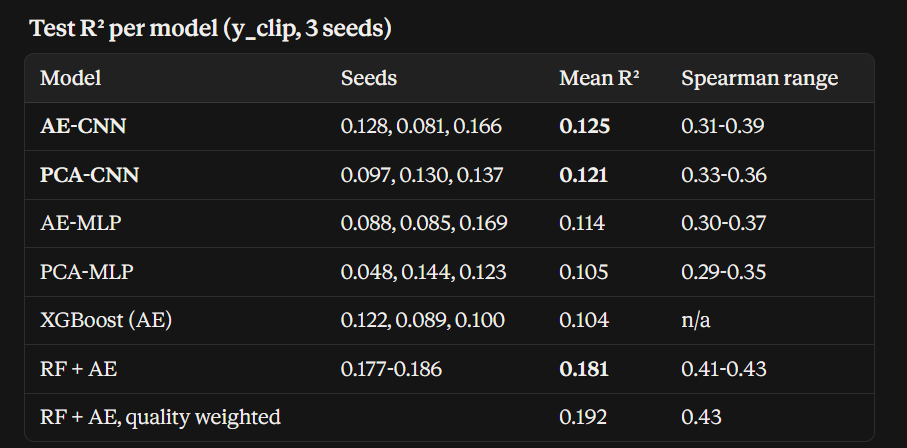

In [23]:
import glob
for name in ["cnn_ae", "mlp_ae", "cnn_pca", "mlp_pca"]:
    P = np.mean([pd.read_csv(RESULTS_DIR/f"pred_{name}_s{s}.csv")["pred_clip"].values for s in [42,43,44]], 0)
    print(name, "ensemble R2 %.4f MAE %.4f rho %.4f" % (r2_score(y_test_clip,P), mean_absolute_error(y_test_clip,P), spearmanr(y_test_clip,P)[0]))

for s in [42, 43, 44]:
    v, ep, p = run_nn(TwoBranchCNN, "ae", s, w=train["w_quality"].values)
    pd.DataFrame({"pred_clip": p}).to_csv(RESULTS_DIR / f"pred_cnn_ae_qual_s{s}.csv", index=False)
    print("cnn-ae quality s%d | ep %d val %.4f | test R2 %.4f rho %.4f" % (s, ep, v, r2_score(y_test_clip,p), spearmanr(y_test_clip,p)[0]))

cnn_ae ensemble R2 0.1353 MAE 0.5481 rho 0.3624
mlp_ae ensemble R2 0.1215 MAE 0.5545 rho 0.3481
cnn_pca ensemble R2 0.1350 MAE 0.5428 rho 0.3716
mlp_pca ensemble R2 0.1154 MAE 0.5574 rho 0.3321
cnn-ae quality s42 | ep 31 val 0.5727 | test R2 0.1535 rho 0.3055
cnn-ae quality s43 | ep 10 val 0.5790 | test R2 0.1072 rho 0.3271
cnn-ae quality s44 | ep 21 val 0.5783 | test R2 0.1739 rho 0.3869


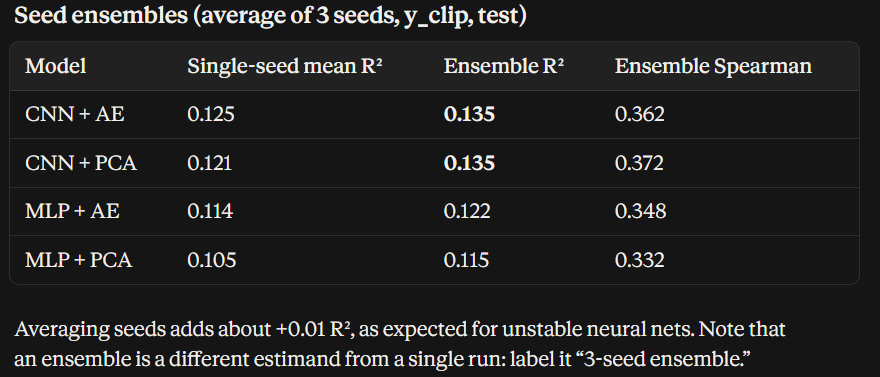

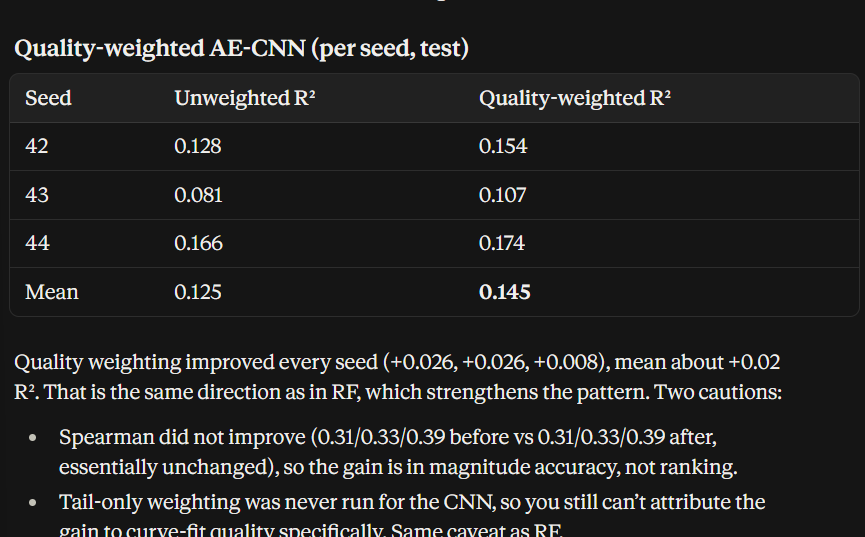

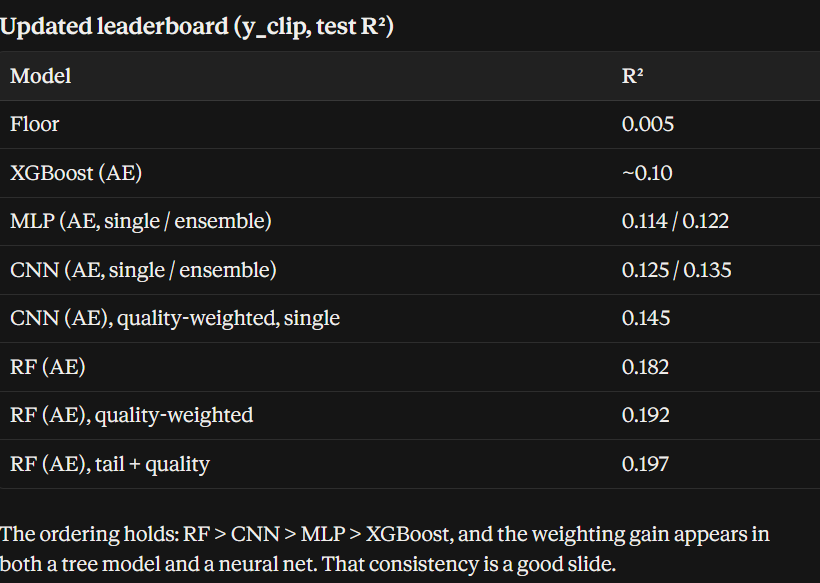